Given an unsorted integer array nums. Return the smallest positive integer that is not present in nums.

You must implement an algorithm that runs in O(n) time and uses O(1) auxiliary space.



Example 1:

Input: nums = [1,2,0]
Output: 3
Explanation: The numbers in the range [1,2] are all in the array.
Example 2:

Input: nums = [3,4,-1,1]
Output: 2
Explanation: 1 is in the array but 2 is missing.
Example 3:

Input: nums = [7,8,9,11,12]
Output: 1
Explanation: The smallest positive integer 1 is missing.


Constraints:

1 <= nums.length <= 105
-231 <= nums[i] <= 231 - 1

In [ ]:
fun firstMissingPositive(nums: IntArray): Int {
    val freq = IntArray(2.0.pow(31).toInt() - 1)

    for(i in nums) {
        if (i > 0) {
            freq[i-1] = 1
        }
    }

    for (i in freq.indices) {
        if (freq[i] < 1) {
            return i+1
        }
    }

    return 1
}

Решение не удачное - Не учтены накладные по памяти

In [ ]:
fun firstMissingPositive(nums: IntArray): Int {
    val freq = HashSet<Int>()

    for(i in nums.indices) {
        if (nums[i] > 0) {
            freq.add(nums[i])
        }
    }

    for (i in 1..Int.MAX_VALUE) {
        if (i !in freq) {
            return i
        }
    }

    return 1
}

In [ ]:
fun firstMissingPositive(nums: IntArray): Int {
    nums.forEachIndexed { i, num ->
        if (num < 0 || num > nums.size)
            nums[i] = 0
    }

    var i = 0

    while (i < nums.size) {
        val num = nums[i]

        if (num == 0 || num == i+1)
            i++
        else {
            val tmp = nums[num-1]
            nums[num - 1] = num
            nums[i] = tmp
        }
    }

    nums.forEachIndexed { ind, num ->
        if (num == 0) return ind+1
    }

    return nums.size + 1
}

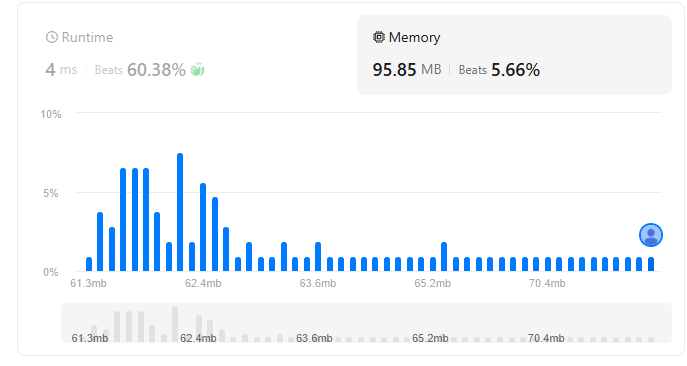